In [ ]:
!test -d /content/forecasting || git clone https://github.com/interpolants/forecasting.git /content/forecasting
%cd /content/forecasting/navier-stokes

Cloning into '/content/forecasting'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 22 (delta 1), reused 0 (delta 0), pack-reused 14 (from 2)
Receiving objects: 100% (22/22), 46.48 MiB | 20.53 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/forecasting/navier-stokes


In [ ]:
!pip install -q jax-cfd wandb einops

In [ ]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import wandb
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import seaborn as sns
import xarray
import torch
import numpy as np

import jax_cfd.base as cfd
# import jax_cfd.base.forcings as forcings
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral

# from jax_cfd.base import boundaries
# from jax_cfd.base import forcings
# from jax_cfd.base import grids
from jax_cfd.spectral import forcings as spectral_forcings
from jax_cfd.spectral import time_stepping
from jax_cfd.spectral import types
from jax_cfd.spectral import utils as spectral_utils

#from jax.experimental.host_callback import call

from functools import partial

from typing import Callable, Optional, Tuple
Array = grids.Array
GridArrayVector = grids.GridArrayVector
GridVariableVector = grids.GridVariableVector
ForcingFn = Callable[[GridVariableVector], GridArrayVector]

import dataclasses

import os

from jax import config

GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0.0
# config.update("jax_enable_x64", True)


In [ ]:
class NavierStokes2D:
    """Breaks the Navier-Stokes equation into implicit and explicit parts.

    Implicit parts are the linear terms and explicit parts are the non-linear
    terms.

    Attributes:
    viscosity: strength of the diffusion term
    grid: underlying grid of the process
    smooth: smooth the advection term using the 2/3-rule.
    forcing_fn: forcing function, if None then no forcing is used.
    drag: strength of the drag. Set to zero for no drag.
    """

    def __init__(self,viscosity: float,
                 grid: grids.Grid,
                 drag: float = 0.,
                 dt: float = 1e-3,
                 noise_scale: float = 1e-2,
                 smooth: bool = True,):

        self.viscosity = viscosity
        self.grid = grid
        self.drag = drag
        self.dt = dt
        self.noise_scale = noise_scale
        self.smooth = smooth

        self.kx, self.ky = self.grid.rfft_mesh()
        self.laplace = (jnp.pi * 2j)**2 * (self.kx**2 + self.ky**2)
        self.filter_ = spectral_utils.brick_wall_filter_2d(self.grid)
        self.linear_term = self.viscosity * self.laplace - self.drag
        self.offsets = (0,0)
        self.x = self.grid.mesh(self.offsets)[0]
        self.y = self.grid.mesh(self.offsets)[1]

    # setup the forcing function with the caller-specified grid.

    @partial(jax.jit, static_argnums=0)
    def explicit_terms(self, vorticity_hat, key):
        velocity_solve = spectral_utils.vorticity_to_velocity(self.grid)
        vxhat, vyhat = velocity_solve(vorticity_hat)
        vx, vy = jnp.fft.irfftn(vxhat), jnp.fft.irfftn(vyhat)

        grad_x_hat = 2j * jnp.pi * self.kx * vorticity_hat
        grad_y_hat = 2j * jnp.pi * self.ky * vorticity_hat
        grad_x, grad_y = jnp.fft.irfftn(grad_x_hat), jnp.fft.irfftn(grad_y_hat)

        advection = -(grad_x * vx + grad_y * vy)
        advection_hat = jnp.fft.rfftn(advection)

        randn_noise = self.noise_scale*jax.random.normal(key = key,shape = (4,))/jnp.sqrt(self.dt)

        vorticity_noise = randn_noise[0]*jnp.sin(6*self.x) + randn_noise[1]*jnp.cos(7*self.x) \
                          + randn_noise[2]*jnp.sin(5*(self.x+self.y)) + randn_noise[3]*jnp.cos(8*(self.x+self.y))

        vorticity_noise_hat = jnp.fft.rfft2(vorticity_noise)

        if self.smooth is not None:
            advection_hat *= self.filter_

        terms = advection_hat + vorticity_noise_hat

        return terms

    @partial(jax.jit, static_argnums=0)
    def implicit_terms(self, vorticity_hat):
        return self.linear_term * vorticity_hat

    @partial(jax.jit, static_argnums=0)
    def implicit_solve(self, vorticity_hat, time_step):
        return 1 / (1 - time_step * self.linear_term) * vorticity_hat

    @partial(jax.jit, static_argnums=0)
    def euler_step(self,vorticity_hat,key):

        g = vorticity_hat + self.dt*self.explicit_terms(vorticity_hat,key)
        u1 = self.implicit_solve(g, self.dt)

        return u1


In [ ]:
class Burgers2D:
    """Uses the potential form of forced viscous Burgers' equation

    Only changes from NS in this implementation are
    vx, vy = 0.5 * grad_x, 0.5 * grad_y
    the noise scale
    and the forcing pattern
    """

    def __init__(self,viscosity: float,
                 grid: grids.Grid,
                 drag: float = 0.,
                 dt: float = 1e-3,
                 noise_scale: float = 0.25,
                 smooth: bool = True,):

        self.viscosity = viscosity
        self.grid = grid
        self.drag = drag
        self.dt = dt
        self.noise_scale = noise_scale
        self.smooth = smooth

        self.kx, self.ky = self.grid.rfft_mesh()
        self.laplace = (jnp.pi * 2j)**2 * (self.kx**2 + self.ky**2)
        self.filter_ = spectral_utils.brick_wall_filter_2d(self.grid)
        self.linear_term = self.viscosity * self.laplace - self.drag
        self.offsets = (0,0)
        self.x = self.grid.mesh(self.offsets)[0]
        self.y = self.grid.mesh(self.offsets)[1]

        phases = [a * self.x + b * self.y for a, b in ((1, 0), (0, 1), (1, 1), (1, -1))]
        self.patterns = jnp.stack([f(p) for p in phases for f in (jnp.sin, jnp.cos)])
        self.keep = (self.kx != 0) | (self.ky != 0) # so mean doen't drift

    # setup the forcing function with the caller-specified grid.

    @partial(jax.jit, static_argnums=0)
    def explicit_terms(self, vorticity_hat, key):
        #velocity_solve = spectral_utils.vorticity_to_velocity(self.grid)
        #vxhat, vyhat = velocity_solve(vorticity_hat)
        #vx, vy = jnp.fft.irfftn(vxhat), jnp.fft.irfftn(vyhat)

        grad_x_hat = 2j * jnp.pi * self.kx * vorticity_hat
        grad_y_hat = 2j * jnp.pi * self.ky * vorticity_hat
        grad_x, grad_y = jnp.fft.irfftn(grad_x_hat), jnp.fft.irfftn(grad_y_hat)
        vx, vy = 0.5 * grad_x, 0.5 * grad_y

        advection = -(grad_x * vx + grad_y * vy)
        advection_hat = jnp.fft.rfftn(advection)

        #randn_noise = self.noise_scale*jax.random.normal(key = key,shape = (4,))/jnp.sqrt(self.dt)
        randn_noise = self.noise_scale * jax.random.normal(key=key, shape=(8,)) / jnp.sqrt(self.dt)
        phi_noise_hat = jnp.fft.rfft2(jnp.tensordot(randn_noise, self.patterns, axes=1))

        #vorticity_noise = randn_noise[0]*jnp.sin(6*self.x) + randn_noise[1]*jnp.cos(7*self.x) \
                          #+ randn_noise[2]*jnp.sin(5*(self.x+self.y)) + randn_noise[3]*jnp.cos(8*(self.x+self.y))
        #vorticity_noise_hat = jnp.fft.rfft2(vorticity_noise)

        if self.smooth is not None:
            advection_hat *= self.filter_

        terms = advection_hat + phi_noise_hat

        return terms

    @partial(jax.jit, static_argnums=0)
    def implicit_terms(self, vorticity_hat):
        return self.linear_term * vorticity_hat

    @partial(jax.jit, static_argnums=0)
    def implicit_solve(self, vorticity_hat, time_step):
        return 1 / (1 - time_step * self.linear_term) * vorticity_hat

    @partial(jax.jit, static_argnums=0)
    def euler_step(self,vorticity_hat,key):

        g = vorticity_hat + self.dt*self.explicit_terms(vorticity_hat,key)
        u1 = self.implicit_solve(g, self.dt)

        return u1 * self.keep      # zero the mean of phi


[ 0 10]
finite: True | divergence skewness -4.14 (strongly negative = shock-dominated)


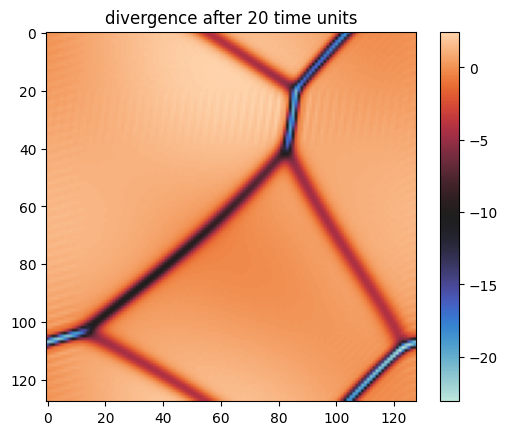

CPU times: user 21.1 s, sys: 2.82 s, total: 23.9 s
Wall time: 29.8 s


In [ ]:
%%time
# test
viscosity = 0.05
rand_seed = 10
dt = 1e-3
key = jax.random.PRNGKey(rand_seed)
print(key)
grid = grids.Grid((128,128), domain=((0, 2 * jnp.pi), (0, 2 * jnp.pi)))
smooth = True
equation = Burgers2D(viscosity,grid,drag=0.0,dt = dt,smooth=smooth)

'''v0 = cfd.initial_conditions.filtered_velocity_field(jax.random.PRNGKey(1), grid, 7, 2)
vorticity0 = cfd.finite_differences.curl_2d(v0).data
vorticity_hat0 = jnp.fft.rfftn(vorticity0)

for i in range(1000):
    key,_ = jax.random.split(key)
#     print(key)
    vorticity_hat1 = equation.euler_step(vorticity_hat0,key)
    vorticity_hat0 = vorticity_hat1

vorticity1 = jnp.fft.irfft2(vorticity_hat0)'''

phi_hat = jnp.zeros((128, 128 // 2 + 1), jnp.complex64) #u=\nabla\phi=0
for i in range(20_000):
    key, sub = jax.random.split(key)
    phi_hat = equation.euler_step(phi_hat, sub)

divergence = np.asarray(jnp.fft.irfft2(equation.laplace * phi_hat))
d = divergence.ravel()
print(f"finite: {np.isfinite(d).all()} | divergence skewness {((d - d.mean())**3).mean() / d.std()**3:+.2f} "
      "(strongly negative = shock-dominated)")
plt.imshow(divergence, cmap=sns.cm.icefire); plt.colorbar(); plt.title("divergence after 20 time units"); plt.show()

# Data generation

In [ ]:
%%time

avg_pixel_norm = 3.0679163932800293 # from utils.py

def burger_data_generation(
    grid_size: int = 256,
    noise_scale: float = 0.25,
    num_trajectories: int = 2,
    viscosity: float = 0.05,
    dt: float = 1e-3,
    spinup_time: float = 50.0,
    time_snapshots: int = 100,
    snapshot_every: float = 0.5,
    seed: int = 0
) -> Tuple[np.ndarray, np.ndarray, float]:

    grid = grids.Grid((grid_size, grid_size), domain=((0, 2 * jnp.pi), (0, 2 * jnp.pi)))
    equation = Burgers2D(viscosity, grid, drag=0.0, dt=dt, noise_scale=noise_scale)
    spinup_steps = int(round(spinup_time / dt))
    inner_steps = int(round(snapshot_every / dt))

    data_all = np.zeros((num_trajectories, time_snapshots, grid_size, grid_size), np.float32)

    for i in range(num_trajectories):

        key = jax.random.PRNGKey(seed + i)
        phi_hat_curr = jnp.zeros((grid_size, grid_size // 2 + 1), jnp.complex64)

        for steps in range(spinup_steps):
            key, sub = jax.random.split(key)
            phi_hat_curr = equation.euler_step(phi_hat_curr, sub)

        for j in range(time_snapshots):

            data_all[i, j] = np.asarray(jnp.fft.irfft2(equation.laplace * phi_hat_curr))   # divergence

            for steps in range(inner_steps):
                key, sub = jax.random.split(key)
                phi_hat_curr = equation.euler_step(phi_hat_curr, sub)

    norm = (np.sqrt((data_all.astype(np.float64) ** 2).sum(axis=(2, 3))) / grid_size).mean()
    scale = float(avg_pixel_norm / norm)
    data_all *= scale                          # their loader divides by avg_pixel_norm
    time = (spinup_time + snapshot_every * np.arange(time_snapshots)).astype(np.float32)
    return data_all, time, scale               # scale turns saved frames back into simulator states

import inspect
BURGERS_SETTINGS = {k: v.default for k, v in inspect.signature(burger_data_generation).parameters.items()}
data_np, time_np, burgers_scale = burger_data_generation(**BURGERS_SETTINGS)

CPU times: user 2min 55s, sys: 22.7 s, total: 3min 18s
Wall time: 2min 47s


data (2, 100, 256, 256) float32 | time (100,): 50.0 ... 99.5
finite values only: True   (False = the run blew up)
average frame RMS after their normalization: 1.000   (should be 1.000)
largest frame mean: 1.9e-08   (should be ~0: a divergence has zero mean)
divergence skewness: -5.01   (strongly negative = shock-dominated; near 0 = forcing too weak)
correlation with the frame 2 later (their time_lag): 0.29
correlation between trajectories at the same frame: -0.08   (should be near 0)
power at k = 83 relative to the peak: 6.6e-06   (small = shocks resolved)


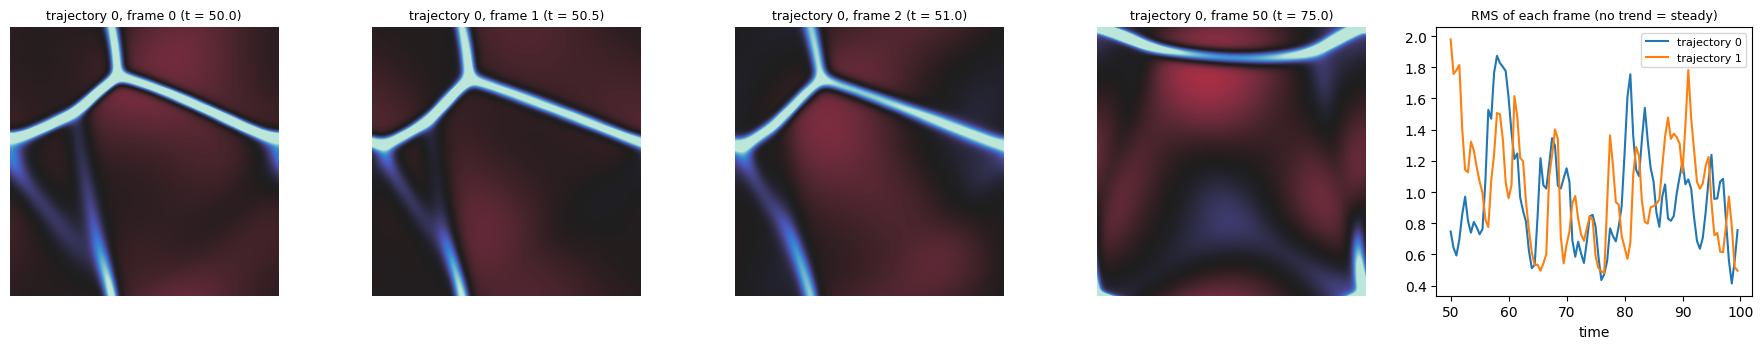

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

x = data_np / avg_pixel_norm
n_traj, n_frames, N, _ = x.shape
rms = np.sqrt((x.astype(np.float64) ** 2).mean(axis=(2, 3)))
sample = x[:, ::5].ravel()
skew = ((sample - sample.mean()) ** 3).mean() / sample.std() ** 3


def corr(a, b):
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


lag2 = np.mean([corr(x[i, t], x[i, t + 2]) for i in range(n_traj) for t in range(n_frames - 2)])

k = np.fft.fftfreq(N, 1 / N)
kk = np.sqrt(k[:, None] ** 2 + np.fft.rfftfreq(N, 1 / N)[None, :] ** 2).round().astype(int)
power = (np.abs(np.fft.rfft2(x[:, ::10])) ** 2).reshape(-1, N, N // 2 + 1).mean(0)
spectrum = np.bincount(kk.ravel(), weights=power.ravel())
k_top = N // 3 - 2

print(f"data {data_np.shape} {data_np.dtype} | time {time_np.shape}: {time_np[0]} ... {time_np[-1]}")
print(f"finite values only: {np.isfinite(data_np).all()}   (False = the run blew up)")
print(f"average frame RMS after their normalization: {rms.mean():.3f}   (should be 1.000)")
print(f"largest frame mean: {np.abs(x.mean(axis=(2, 3))).max():.1e}   (should be ~0: a divergence has zero mean)")
print(f"divergence skewness: {skew:+.2f}   (strongly negative = shock-dominated; near 0 = forcing too weak)")
print(f"correlation with the frame 2 later (their time_lag): {lag2:.2f}")
if n_traj > 1:
    print(f"correlation between trajectories at the same frame: {corr(x[0, 0], x[1, 0]):+.2f}   (should be near 0)")
print(f"power at k = {k_top} relative to the peak: {spectrum[k_top] / spectrum[1:].max():.1e}   "
      "(small = shocks resolved)")

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, t in zip(axes[:4], (0, 1, 2, n_frames // 2)):
    ax.imshow(x[0, t], cmap=sns.cm.icefire, vmin=-2, vmax=2)
    ax.set_title(f"trajectory 0, frame {t} (t = {time_np[t]:.1f})", fontsize=9)
    ax.axis("off")
for i in range(n_traj):
    axes[4].plot(time_np, rms[i], label=f"trajectory {i}")
axes[4].set_xlabel("time")
axes[4].set_title("RMS of each frame (no trend = steady)", fontsize=9)
axes[4].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
import inspect
import json

DATA_FILE = "burgers_data.pt"
torch.save((torch.from_numpy(data_np), torch.from_numpy(time_np)), DATA_FILE)

with open(DATA_FILE.replace(".pt", "_info.json"), "w") as f:     # the settings used, and the scale factor
    json.dump(dict(BURGERS_SETTINGS, field="divergence of the velocity", scaled_to_average_norm=avg_pixel_norm,
                   scale_applied=burgers_scale), f, indent=1)

data_raw, time_raw = torch.load(DATA_FILE)
print(f"saved {DATA_FILE}: data {tuple(data_raw.shape)} {data_raw.dtype}, time {tuple(time_raw.shape)}; "
      f"identical on reload: {torch.equal(data_raw, torch.from_numpy(data_np))}")

saved burgers_data.pt: data (2, 100, 256, 256) torch.float32, time (100,); identical on reload: True


# Set up training

In [ ]:
DATA_DIR = "."                     # the repo's navier-stokes folder (the working directory)
NSE_FILE = "nse_data_tiny.pt"      # their data
BURGERS_FILE = "burgers_data.pt"   # saved by the save cell above

DATASET = "mixed"        # "nse", "burgers" or "mixed"
BURGERS_FRACTION = 0.5   # for mixed
TRAIN_FRAMES = (0, 80)   # train on these frames; the evaluation section starts its forecasts from frames 84-96


def train_part(path):
    data, t = torch.load(path)
    a, b = TRAIN_FRAMES
    return data[:, a:b].clone(), t[a:b].clone()


nse_data, nse_time = train_part(NSE_FILE)
if DATASET == "nse":
    SYSTEMS = {"Navier–Stokes": (0, nse_data.shape[0])}
    tr_data, tr_time = nse_data, nse_time
else:
    b_data, b_time = train_part(BURGERS_FILE)
    if DATASET == "burgers":
        SYSTEMS = {"Burgers": (0, b_data.shape[0])}
        tr_data, tr_time = b_data, b_time
    else:
        assert nse_data.shape[1:] == b_data.shape[1:], "frame count and grid must match to stack trajectories"
        n = nse_data.shape[0]
        SYSTEMS = {"Navier–Stokes": (0, n), "Burgers": (n, n + b_data.shape[0])}
        tr_data, tr_time = torch.cat([nse_data, b_data], 0), nse_time

DATA_FILE = os.path.join(DATA_DIR, f"{DATASET}_train.pt")      # what the training cells read
torch.save((tr_data, tr_time), DATA_FILE)
print(f"{DATASET}: {DATA_FILE} {tuple(tr_data.shape)}, frames {TRAIN_FRAMES[0]}-{TRAIN_FRAMES[1] - 1}; "
      f"trajectory ranges {SYSTEMS}")

mixed: ./mixed_train.pt (4, 80, 256, 256), frames 0-79; trajectory ranges {'Navier–Stokes': (0, 2), 'Burgers': (2, 4)}


In [ ]:
import os
import numpy as np
import torch
import main, utils, interpolant

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)

conf = main.Config(dataset="nse", debug=False, overfit=False, sigma_coef=1.0, beta_fn="t^2")  # main.py, Config
conf.data_fname = DATA_FILE
conf.batch_size = 32 if GPU_MEM_GB > 35 else 16 if GPU_MEM_GB > 20 else 8
conf.use_wandb = False

loader, old_pixel_norm, _ = utils.get_forecasting_dataloader(conf, shuffle=True)
pairs = loader.dataset                               # their TensorDataset of (condition, target) pairs
per_traj = len(pairs) // sum(b - a for a, b in SYSTEMS.values())

if DATASET == "mixed" and BURGERS_FRACTION is not None:   # draw Burgers pairs with the chosen probability
    first, last = SYSTEMS["Burgers"]                 # Burgers pairs follow the Navier-Stokes ones
    is_burgers = torch.zeros(len(pairs), dtype=torch.bool)
    is_burgers[first * per_traj: last * per_traj] = True
    w = torch.where(is_burgers, BURGERS_FRACTION / is_burgers.sum(), (1 - BURGERS_FRACTION) / (~is_burgers).sum())
    sampler = torch.utils.data.WeightedRandomSampler(w.double(), num_samples=len(pairs), replacement=True)
    loader = torch.utils.data.DataLoader(pairs, batch_size=conf.batch_size, sampler=sampler)

model = utils.DriftModel(conf).to(device)
                                                     # condition concatenated as a second input channel
I = interpolant.Interpolant(conf)                    # interpolant.py: alpha, beta, sigma, gamma
optimizer = torch.optim.AdamW(model.parameters(), lr=conf.base_lr)
U = torch.distributions.Uniform(low=conf.t_min_train, high=conf.t_max_train)
step, losses = 0, []
print(f"{len(pairs)} training pairs ({per_traj} per trajectory), batch size {conf.batch_size}")

SELF DEBUG IS False
making ./tmp_images/
OVERFIT MODE (USEFUL FOR DEBUGGING) IS False
NOT USING CLASSES IN UNET
Num params in main arch for drift is 29,988,753
312 training pairs (78 per trajectory), batch size 8


In [ ]:
TRAIN_STEPS = 2000
batches = iter(loader)
for _ in range(TRAIN_STEPS):
    try:
        xlo, xhi = next(batches)
    except StopIteration:
        batches = iter(loader)
        xlo, xhi = next(batches)

    with torch.no_grad():
        D = {"z0": xlo.to(device), "z1": xhi.to(device), "label": None, "N": xlo.shape[0]}
        D["t"] = U.sample(sample_shape=(D["N"],)).to(device)    # Trainer.get_time: one random time per pair
        D["cond"] = D["z0"]                          # the network is conditioned on the start
        D["noise"] = torch.randn_like(D["z0"])
        D = I.interpolant_coefs(D)                   # alpha, beta, sigma, gamma and their time derivatives
        D["zt"] = I.compute_zt(D)                    # x_t = alpha * z0 + beta * z1 + gamma * noise
        D["drift_target"] = I.compute_target(D)     # alpha' * z0 + beta' * z1 + sigma' * sqrt(t) * noise

    model.train()
    out = model(D["zt"], D["t"], D["label"], cond=D["cond"])
    loss = (out - D["drift_target"]).pow(2).sum(-1).sum(-1).sum(-1).mean()    # Trainer.image_sq_norm
    loss.backward()

    utils.clip_grad_norm(model, max_norm=conf.max_grad_norm)
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    step += 1
    losses.append(loss.item())
    if step % conf.print_loss_every == 0:            # every 100 steps
        print(f"Grad step {step}. Loss: {np.mean(losses[-conf.print_loss_every:]):.4f}")

Grad step 100. Loss: 10072.3272
Grad step 200. Loss: 4398.5068
Grad step 300. Loss: 3639.4840
Grad step 400. Loss: 3408.1863
Grad step 500. Loss: 2906.3190
Grad step 600. Loss: 2912.2766
Grad step 700. Loss: 2664.6890
Grad step 800. Loss: 2564.0221
Grad step 900. Loss: 2458.9448
Grad step 1000. Loss: 2300.5294
Grad step 1100. Loss: 2307.3665
Grad step 1200. Loss: 2156.8187
Grad step 1300. Loss: 2207.0899
Grad step 1400. Loss: 2176.0490
Grad step 1500. Loss: 1977.3156
Grad step 1600. Loss: 1988.7876
Grad step 1700. Loss: 1934.9905
Grad step 1800. Loss: 2061.4404
Grad step 1900. Loss: 1900.7252
Grad step 2000. Loss: 1857.4808


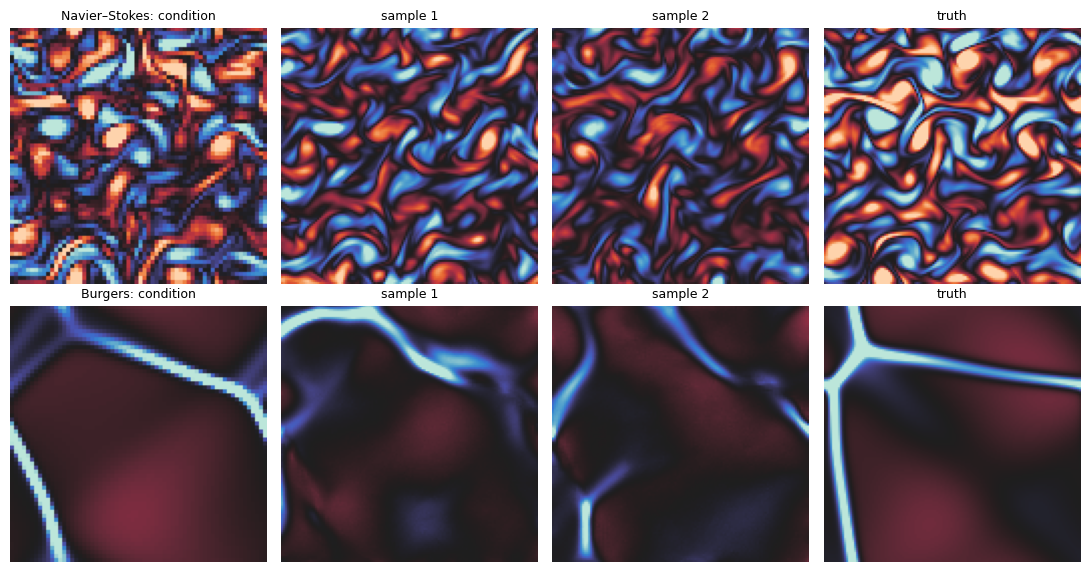

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


@torch.no_grad()
def forecast(z0, n_samples=2, steps=conf.EM_sample_steps):
    """Euler-Maruyama from the point mass at z0, as Trainer.EM with diffusion_fn=None."""
    model.eval()
    base = z0.to(device).repeat_interleave(n_samples, 0)
    ts = torch.linspace(conf.t_min_sampling, conf.t_max_sampling, steps, device=device)   # 0 to 0.999
    dt = ts[1] - ts[0]
    xt = base
    for t in ts:
        t = t * torch.ones(base.shape[0], device=device)
        drift = model(xt, t, None, cond=base)        # the learned drift, conditioned on the start
        mu = xt + drift * dt
        xt = mu + I.sigma(t) * torch.randn_like(mu) * dt.sqrt()   # sigma(t) = sigma_coef * (1 - t)
    return mu.reshape(z0.shape[0], n_samples, *mu.shape[1:]).cpu()


lo, hi = pairs.tensors                               # conditions and targets, in their normalized units
idx = [first * per_traj + 5 for first, _ in SYSTEMS.values()]      # frame 5 of each system's first trajectory
samples = forecast(lo[idx])
fig, axes = plt.subplots(len(idx), 4, figsize=(11, 2.9 * len(idx)), squeeze=False)
for r, (i, name) in enumerate(zip(idx, SYSTEMS)):
    panels = [lo[i, 0], samples[r, 0, 0], samples[r, 1, 0], hi[i, 0]]
    for c, (img, title) in enumerate(zip(panels, ["condition", "sample 1", "sample 2", "truth"])):
        axes[r, c].imshow(img.numpy(), cmap=sns.cm.icefire, vmin=-2, vmax=2)   #make_one_redblue_plot
        axes[r, c].set_title(f"{name}: {title}" if c == 0 else title, fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("ckpts", exist_ok=True)
torch.save({"model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "step": step, "train_frames": TRAIN_FRAMES, "dataset": DATASET}, f"ckpts/{DATASET}.pt")
print(f"saved ckpts/{DATASET}.pt at step {step}")
#ckpt = torch.load(f"ckpts/{DATASET}.pt"); model.load_state_dict(ckpt["model_state_dict"]);
#optimizer.load_state_dict(ckpt["optimizer_state_dict"]); step = ckpt["step"]

saved ckpts/mixed.pt at step 2000


# Baseline

In [ ]:
DET_STEPS = 2000
det_model = utils.DriftModel(conf).to(device)                 # same network as the forecaster
det_optimizer = torch.optim.AdamW(det_model.parameters(), lr=conf.base_lr)
det_losses = []
batches = iter(loader)
for det_step in range(1, DET_STEPS + 1):
    try:
        xlo, xhi = next(batches)
    except StopIteration:
        batches = iter(loader)
        xlo, xhi = next(batches)
    z0, z1 = xlo.to(device), xhi.to(device)
    det_model.train()
    pred = det_model(z0, torch.zeros(z0.shape[0], device=device), None, cond=z0)   # time input fixed at 0
    loss = (pred - z1).pow(2).sum(-1).sum(-1).sum(-1).mean()   # squared error, as in Trainer.training_step
    loss.backward()
    utils.clip_grad_norm(det_model, max_norm=conf.max_grad_norm)
    det_optimizer.step()
    det_optimizer.zero_grad(set_to_none=True)
    det_losses.append(loss.item())
    if det_step % conf.print_loss_every == 0:
        print(f"Grad step {det_step}. Loss: {np.mean(det_losses[-conf.print_loss_every:]):.4f}")

os.makedirs("ckpts", exist_ok=True)
torch.save({"model_state_dict": det_model.state_dict(), "optimizer_state_dict": det_optimizer.state_dict(),
            "step": DET_STEPS, "train_frames": TRAIN_FRAMES, "dataset": DATASET}, f"ckpts/{DATASET}_deterministic.pt")
print(f"saved ckpts/{DATASET}_deterministic.pt")

NOT USING CLASSES IN UNET
Num params in main arch for drift is 29,988,753
Grad step 100. Loss: 15726.6829
Grad step 200. Loss: 13944.8841
Grad step 300. Loss: 13862.5574
Grad step 400. Loss: 13710.2653
Grad step 500. Loss: 14206.2604
Grad step 600. Loss: 14022.1399
Grad step 700. Loss: 13655.7033
Grad step 800. Loss: 13621.7760
Grad step 900. Loss: 12787.7293
Grad step 1000. Loss: 12568.4206
Grad step 1100. Loss: 12169.2685
Grad step 1200. Loss: 11575.7551
Grad step 1300. Loss: 11671.0791
Grad step 1400. Loss: 11448.2661
Grad step 1500. Loss: 10436.0570
Grad step 1600. Loss: 9849.6227
Grad step 1700. Loss: 9149.4912
Grad step 1800. Loss: 8650.9185
Grad step 1900. Loss: 7562.3189
Grad step 2000. Loss: 6975.6294
saved ckpts/mixed_deterministic.pt


# Evaluation

In [ ]:
import json
import time as timer
import pandas as pd
import scipy.integrate
import scipy.stats

START_FRAMES = (84, 90, 96)   # held-out starting frames in every trajectory
N_MEMBERS = 16                # forecasts per start, for each model and for the simulator reference
EM_STEPS = 200                # Euler-Maruyama steps per forecast
LAG = conf.time_lag           # frames ahead, as in training: 2 frames = 1 time unit
K_MAX = 40                    # largest wavenumber compared in the spectra of the 128 x 128 fields
NSE_SETTINGS = dict(viscosity=1e-3, drag=0.1, noise_scale=1.0, dt=1e-4)
RUN_ROLLOUT = True
ROLLOUT_STEPS = 20
ROLLOUT_EM_STEPS = 100

assert min(START_FRAMES) >= TRAIN_FRAMES[1], "the starting frames must not be training frames"
with open(BURGERS_FILE.replace(".pt", "_info.json")) as f:
    BURGERS_INFO = json.load(f)
assert "scale_applied" in BURGERS_INFO, "re-run the generation and save cells: the Burgers scale factor is needed"

COVERS = {"nse": ["Navier–Stokes"], "burgers": ["Burgers"], "mixed": ["Navier–Stokes", "Burgers"]}
MODELS = {}                   # name -> (network, "sde" or "det", systems it was trained on)
for name in ("nse", "burgers", "mixed"):
    for suffix, kind in (("", "sde"), ("_deterministic", "det")):
        path = f"ckpts/{name}{suffix}.pt"
        if not os.path.exists(path):
            continue
        ckpt = torch.load(path, map_location=device)
        if tuple(ckpt.get("train_frames", ())) != tuple(TRAIN_FRAMES):
            print(f"skipping {path}: not trained on frames {TRAIN_FRAMES} (retrain it after the dataset cell)")
            continue
        net = utils.DriftModel(conf).to(device)
        net.load_state_dict(ckpt["model_state_dict"])
        net.eval()
        MODELS[name + suffix] = (net, kind, COVERS[name])
        print(f"loaded {path}: {kind}, step {ckpt['step']}, trained on {' and '.join(COVERS[name])}")
assert MODELS, "no models trained on the training frames found in ckpts/"

NOT USING CLASSES IN UNET
Num params in main arch for drift is 29,988,753
loaded ckpts/mixed.pt: sde, step 2000, trained on Navier–Stokes and Burgers
NOT USING CLASSES IN UNET
Num params in main arch for drift is 29,988,753
loaded ckpts/mixed_deterministic.pt: det, step 2000, trained on Navier–Stokes and Burgers


In [ ]:
# Metrics
def model_view(frames):
    """Raw frames (n, 256, 256) -> (conditions, targets), each (n, 128, 128), via their utils.maybe_downsample:
    targets are bilinear to 128 x 128; conditions are bilinear to 64 x 64, then nearest back to 128 x 128."""
    x = torch.as_tensor(np.asarray(frames, np.float32))[None] / avg_pixel_norm
    lo, hi = utils.maybe_downsample(x, x, conf.lo_size, conf.hi_size)
    return lo[0].numpy(), hi.numpy()


_k = np.fft.fftfreq(conf.hi_size, 1 / conf.hi_size)
K2 = _k[:, None] ** 2 + _k[None, :] ** 2
RING = np.floor(np.sqrt(K2)).astype(int)                     # ring k: the modes with k <= |m| < k + 1
INV_K2 = np.where(K2 > 0, 1 / np.where(K2 > 0, K2, 1), 0)


def enstrophy_spectrum(fields):
    """The paper's Enstrophy(k): the sum of |w_hat(m)|^2 over the ring k, averaged over the fields."""
    power = (np.abs(np.fft.fft2(fields)) ** 2).reshape(-1, *RING.shape).mean(0)
    return np.bincount(RING.ravel(), weights=power.ravel())[: K_MAX + 1]


def total_enstrophy(fields):                                  # the squared L2 norm of each field
    return (np.asarray(fields, np.float64) ** 2).sum((-2, -1))


def total_energy(fields):                                     # sum of |w_hat|^2 / |k|^2: energy up to a constant
    return (np.abs(np.fft.fft2(fields)) ** 2 * INV_K2).sum((-2, -1))


def rel_l2(a, b):
    return float(np.linalg.norm(a - b) / np.linalg.norm(b))


def kl_kde(ref, est, n_grid=512):
    """KL(reference || estimate) between two 1D sample sets, from Gaussian kernel density estimates (Table 3)."""
    ref, est = np.asarray(ref, np.float64), np.asarray(est, np.float64)
    if ref.std() == 0 or est.std() == 0:
        return float("nan")                                   # e.g. a deterministic model: identical members
    lo, hi = min(ref.min(), est.min()), max(ref.max(), est.max())
    grid = np.linspace(lo - 0.5 * (hi - lo), hi + 0.5 * (hi - lo), n_grid)
    p, q = scipy.stats.gaussian_kde(ref)(grid), scipy.stats.gaussian_kde(est)(grid)
    p, q = p / scipy.integrate.trapezoid(p, grid), q / scipy.integrate.trapezoid(q, grid)
    return float(scipy.integrate.trapezoid(p * np.log((p + 1e-300) / (q + 1e-300)), grid))


def fair_crps(ens, truth):
    """Pixel-averaged CRPS of an ensemble (m, H, W) against one truth (H, W), with the unbiased m(m-1) term."""
    m = ens.shape[0]
    skill = np.abs(ens - truth[None]).mean(0)
    if m == 1:
        return float(skill.mean())
    spread = np.abs(ens[:, None] - ens[None, :]).sum((0, 1)) / (2 * m * (m - 1))
    return float((skill - spread).mean())


PER_START = ["mean_err", "std_err", "kl_enstrophy", "kl_energy", "crps", "mean_err_vs_truth"]   # lower is better
NAMES = {"mean_err": "error of mean", "std_err": "error of std", "spectrum_err": "spectrum error",
         "kl_enstrophy": "KL enstrophy", "kl_energy": "KL energy", "crps": "CRPS vs truth",
         "mean_err_vs_truth": "mean vs truth", "spread_skill": "spread/skill"}


def score(ens, ref, truth):
    """Metrics for one system. ens, ref: (starts, members, H, W); truth: (starts, H, W). Per-start metrics are
    returned as arrays (one value per start); the spectrum error and spread/skill are pooled over starts."""
    S, m = ens.shape[:2]
    out = {
        "mean_err": [rel_l2(ens[s].mean(0), ref[s].mean(0)) for s in range(S)],
        "std_err": [rel_l2(ens[s].std(0, ddof=1), ref[s].std(0, ddof=1)) for s in range(S)],
        "kl_enstrophy": [kl_kde(total_enstrophy(ref[s]), total_enstrophy(ens[s])) for s in range(S)],
        "kl_energy": [kl_kde(total_energy(ref[s]), total_energy(ens[s])) for s in range(S)],
        "crps": [fair_crps(ens[s], truth[s]) for s in range(S)],
        "mean_err_vs_truth": [rel_l2(ens[s].mean(0), truth[s]) for s in range(S)],
    }
    out = {k: np.array(v) for k, v in out.items()}
    out["spectrum_err"] = float(np.mean(np.abs(np.log10(enstrophy_spectrum(ens)[1:] / enstrophy_spectrum(ref)[1:]))))
    spread2 = np.mean([ens[s].var(0, ddof=1).mean() for s in range(S)])
    mse = np.mean([((ens[s].mean(0) - truth[s]) ** 2).mean() for s in range(S)])
    out["spread_skill"] = float(np.sqrt(spread2 / mse * (m + 1) / m))
    return out


def summary(metrics):
    return {NAMES[k]: (np.nanmean(v) if k in PER_START else v) for k, v in metrics.items()}

In [ ]:
class NSE(NavierStokes2D):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        x, y = self.x, self.y
        self.patterns = jnp.stack([jnp.sin(6 * x), jnp.cos(7 * x), jnp.sin(5 * (x + y)), jnp.cos(8 * (x + y)),
                                   jnp.cos(6 * x), jnp.sin(7 * x), jnp.cos(5 * (x + y)), jnp.sin(8 * (x + y))])

    @partial(jax.jit, static_argnums=0)
    def explicit_terms(self, vorticity_hat, key):
        velocity_solve = spectral_utils.vorticity_to_velocity(self.grid)
        vxhat, vyhat = velocity_solve(vorticity_hat)
        vx, vy = jnp.fft.irfftn(vxhat), jnp.fft.irfftn(vyhat)
        grad_x = jnp.fft.irfftn(2j * jnp.pi * self.kx * vorticity_hat)
        grad_y = jnp.fft.irfftn(2j * jnp.pi * self.ky * vorticity_hat)
        advection_hat = jnp.fft.rfftn(-(grad_x * vx + grad_y * vy)) * self.filter_
        randn_noise = self.noise_scale * jax.random.normal(key=key, shape=(8,)) / jnp.sqrt(self.dt)
        return advection_hat + jnp.fft.rfft2(jnp.tensordot(randn_noise, self.patterns, axes=1))


def run_members(equation, starts_hat, n_members, n_steps, seed=0):
    """n_members noise realizations from each start (starts, N, N//2+1), advanced n_steps with euler_step."""
    w = jnp.repeat(starts_hat, n_members, axis=0)
    step = jax.vmap(equation.euler_step)

    def body(_, carry):
        w, key = carry
        key, sub = jax.random.split(key)
        return step(w, jax.random.split(sub, w.shape[0])), key

    w, _ = jax.lax.fori_loop(0, n_steps, body, (w, jax.random.PRNGKey(seed)))
    return w.reshape((starts_hat.shape[0], n_members) + w.shape[1:])


def starts_of(data):
    """Starting frames and the true frames LAG later, from every trajectory: two arrays (starts, H, W)."""
    assert max(START_FRAMES) + LAG < data.shape[1]
    idx = [(i, t) for i in range(data.shape[0]) for t in START_FRAMES]
    return (np.stack([data[i, t].numpy() for i, t in idx]), np.stack([data[i, t + LAG].numpy() for i, t in idx]))


def add_system(name, x0, x1, members):
    """Store conditions, truths and reference members for one system, all as the model sees them."""
    S, M2 = members.shape[:2]
    cond, _ = model_view(x0)
    _, truth = model_view(x1)
    _, mem = model_view(members.reshape(S * M2, *members.shape[2:]))
    mem = mem.reshape(S, M2, *mem.shape[1:])
    EVAL[name] = dict(cond=cond, truth=truth, ref=mem[:, :N_MEMBERS], control=mem[:, N_MEMBERS:])


EVAL = {}
nse_all, nse_t = torch.load(NSE_FILE)
b_all, b_t = torch.load(BURGERS_FILE)

t0 = timer.time()                         # Navier-Stokes: start directly from the stored vorticity
x0, x1 = starts_of(nse_all)
nse_eq = NSE(NSE_SETTINGS["viscosity"], grids.Grid(x0.shape[-2:], domain=((0, 2 * jnp.pi), (0, 2 * jnp.pi))),
                  drag=NSE_SETTINGS["drag"], dt=NSE_SETTINGS["dt"], noise_scale=NSE_SETTINGS["noise_scale"])
n_steps = int(round(LAG * float(nse_t[1] - nse_t[0]) / NSE_SETTINGS["dt"]))
w = run_members(nse_eq, jnp.fft.rfft2(jnp.asarray(x0)), 2 * N_MEMBERS, n_steps, seed=1)
add_system("Navier–Stokes", x0, x1, np.asarray(jnp.fft.irfft2(w)))
print(f"Navier–Stokes reference: {x0.shape[0]} starts x {2 * N_MEMBERS} members, {n_steps} steps, "
      f"{timer.time() - t0:.0f}s")

t0 = timer.time()                         # Burgers: turn the stored divergence back into the potential phi
x0, x1 = starts_of(b_all)
scale = BURGERS_INFO["scale_applied"]
b_eq = Burgers2D(BURGERS_INFO["viscosity"], grids.Grid(x0.shape[-2:], domain=((0, 2 * jnp.pi), (0, 2 * jnp.pi))),
                 drag=0.0, dt=BURGERS_INFO["dt"], noise_scale=BURGERS_INFO["noise_scale"])
lap = b_eq.laplace
d_hat = jnp.fft.rfft2(jnp.asarray(x0 / scale))                # the divergence in simulator units
phi_hat = jnp.where(lap == 0, 0, d_hat / jnp.where(lap == 0, 1, lap))   # divergence = lap(phi)
n_steps = int(round(LAG * BURGERS_INFO["snapshot_every"] / BURGERS_INFO["dt"]))
w = run_members(b_eq, phi_hat.astype(jnp.complex64), 2 * N_MEMBERS, n_steps, seed=2)
add_system("Burgers", x0, x1, np.asarray(jnp.fft.irfft2(lap * w)) * scale)
print(f"Burgers reference: {x0.shape[0]} starts x {2 * N_MEMBERS} members, {n_steps} steps, {timer.time() - t0:.0f}s")

/tmp/ipykernel_2630/2468445406.py:5: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.as_tensor(np.asarray(frames, np.float32))[None] / avg_pixel_norm


Navier–Stokes reference: 6 starts x 32 members, 9998 steps, 174s
Burgers reference: 6 starts x 32 members, 1000 steps, 12s


In [ ]:
# Does each simulator reproduce the data?
def corr(a, b):
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


SIM_OK = {}
for system, e in EVAL.items():
    allm = np.concatenate([e["ref"], e["control"]], 1)          # (starts, 2 * N_MEMBERS, H, W)
    S, M = allm.shape[:2]
    mm = np.array([np.mean([corr(allm[s, i], allm[s, j]) for i in range(M) for j in range(i + 1, M)])
                   for s in range(S)])
    tm = np.array([np.mean([corr(e["truth"][s], allm[s, i]) for i in range(M)]) for s in range(S)])
    gap, gap_se = (mm - tm).mean(), (mm - tm).std(ddof=1) / np.sqrt(S)
    spread2 = np.mean([allm[s].var(0, ddof=1).mean() for s in range(S)])
    mse = np.mean([((allm[s].mean(0) - e["truth"][s]) ** 2).mean() for s in range(S)])
    ss = float(np.sqrt(spread2 / mse * (M + 1) / M))
    SIM_OK[system] = bool(abs(gap) < max(2 * gap_se, 0.03) and 0.8 < ss < 1.25)
    print(f"{system}: corr(member, member) {mm.mean():.2f}, corr(true frame, member) {tm.mean():.2f} "
          f"(gap {gap:+.3f} ± {gap_se:.3f}); spread/skill against the true frames {ss:.2f} -> "
          + ("consistent with the data" if SIM_OK[system] else
             "NOT consistent: reference-based metrics for this system are uncertain"))

Navier–Stokes: corr(member, member) 0.56, corr(true frame, member) 0.55 (gap +0.006 ± 0.021); spread/skill against the true frames 0.98 -> consistent with the data
Burgers: corr(member, member) 0.28, corr(true frame, member) 0.36 (gap -0.086 ± 0.019); spread/skill against the true frames 1.38 -> NOT consistent: reference-based metrics for this system are uncertain


In [ ]:
# Forecasts from every trained model, N_MEMBERS per held-out start
@torch.no_grad()
def sample_batch(net, kind, base, em_steps):
    """One forecast per condition in base (B, 1, 128, 128): their Trainer.EM with the diffusion coefficient used
    in training (g = sigma), or a deterministic model's single output."""
    if kind == "det":
        return net(base, torch.zeros(base.shape[0], device=device), None, cond=base)
    ts = torch.linspace(conf.t_min_sampling, conf.t_max_sampling, em_steps, device=device)
    dt = ts[1] - ts[0]
    xt = base
    for t in ts:
        t = t * torch.ones(base.shape[0], device=device)
        mu = xt + net(xt, t, None, cond=base) * dt
        xt = mu + I.sigma(t) * torch.randn_like(mu) * dt.sqrt()
    return mu


def forecast_ensemble(net, kind, cond, n, em_steps):
    """n forecasts from each condition (starts, 128, 128) -> (starts, n, 128, 128)."""
    out = []
    for c in cond:
        base = torch.as_tensor(c, device=device)[None, None].repeat(n, 1, 1, 1)
        out.append(sample_batch(net, kind, base, em_steps)[:, 0].float().cpu().numpy())
    return np.stack(out)


FORECASTS = {}                                                # (model, system) -> (starts, N_MEMBERS, 128, 128)
for name, (net, kind, systems) in MODELS.items():
    for system in systems:
        t0 = timer.time()
        torch.manual_seed(0)
        FORECASTS[name, system] = forecast_ensemble(net, kind, EVAL[system]["cond"], N_MEMBERS, EM_STEPS)
        print(f"{name} on {system}: {timer.time() - t0:.0f}s")

mixed on Navier–Stokes: 702s
mixed on Burgers: 703s
mixed_deterministic on Navier–Stokes: 3s
mixed_deterministic on Burgers: 3s


In [ ]:
# Scores for every model on every system it was trained on, then mixed versus single-system, start by start
RESULTS = {}
for system, e in EVAL.items():
    rows = {"simulator (perfect-model floor)": score(e["control"], e["ref"], e["truth"])}
    rows.update({name: score(ens, e["ref"], e["truth"]) for (name, s_), ens in FORECASTS.items() if s_ == system})
    RESULTS[system] = rows
    print(f"\n{system}: {e['truth'].shape[0]} held-out starts, {N_MEMBERS} members each "
          "(lower is better, except spread/skill, which should be about 1)")
    if not SIM_OK[system]:
        print("  caution: the simulator check failed, so the columns that compare with the reference are uncertain;"
              " CRPS vs truth, mean vs truth and spread/skill don't use the reference")
    display(pd.DataFrame({r: summary(m) for r, m in rows.items()}).T.round(4))

for system, single in (("Navier–Stokes", "nse"), ("Burgers", "burgers")):
    rows = RESULTS.get(system, {})
    if single not in rows or "mixed" not in rows:
        continue
    table = []
    for k in PER_START:
        d = rows["mixed"][k] - rows[single][k]
        d = d[np.isfinite(d)]
        se = d.std(ddof=1) / np.sqrt(len(d))
        verdict = ("mixed better" if d.mean() < -2 * se else "mixed worse" if d.mean() > 2 * se
                   else "no clear difference")
        table.append({"metric": NAMES[k], f"{single} only": np.nanmean(rows[single][k]),
                      "mixed": np.nanmean(rows["mixed"][k]), "mixed - single": d.mean(), "± SE": se,
                      "verdict": verdict})
    print(f"\n{system}: mixed (BURGERS_FRACTION {BURGERS_FRACTION}) vs {single} only, paired over the same "
          f"{len(EVAL[system]['truth'])} starts")
    display(pd.DataFrame(table).set_index("metric").round(4))


Navier–Stokes: 6 held-out starts, 16 members each (lower is better, except spread/skill, which should be about 1)


/tmp/ipykernel_2630/2468445406.py:83: RuntimeWarning: Mean of empty slice
  return {NAMES[k]: (np.nanmean(v) if k in PER_START else v) for k, v in metrics.items()}


,error of mean,error of std,KL enstrophy,KL energy,CRPS vs truth,mean vs truth,spectrum error,spread/skill
simulator (perfect-model floor),0.3410,0.2720,0.6229,0.5958,0.3909,0.6976,0.0155,0.9503
mixed,0.7714,0.2995,124.0078,127.7523,0.5124,0.8883,0.1747,0.7240
mixed_deterministic,0.6858,1.0000,NaN,NaN,0.6762,0.8406,0.9013,0.0000



Burgers: 6 held-out starts, 16 members each (lower is better, except spread/skill, which should be about 1)
  caution: the simulator check failed, so the columns that compare with the reference are uncertain; CRPS vs truth, mean vs truth and spread/skill don't use the reference


/tmp/ipykernel_2630/2468445406.py:83: RuntimeWarning: Mean of empty slice
  return {NAMES[k]: (np.nanmean(v) if k in PER_START else v) for k, v in metrics.items()}


,error of mean,error of std,KL enstrophy,KL energy,CRPS vs truth,mean vs truth,spectrum error,spread/skill
simulator (perfect-model floor),0.5540,0.5000,0.2122,0.0987,0.2228,0.7954,0.0967,1.4100
mixed,0.8786,0.5763,46.1566,10.2313,0.2976,0.9438,0.5766,0.7401
mixed_deterministic,1.1339,1.0000,NaN,NaN,0.4258,1.0445,0.5483,0.0000


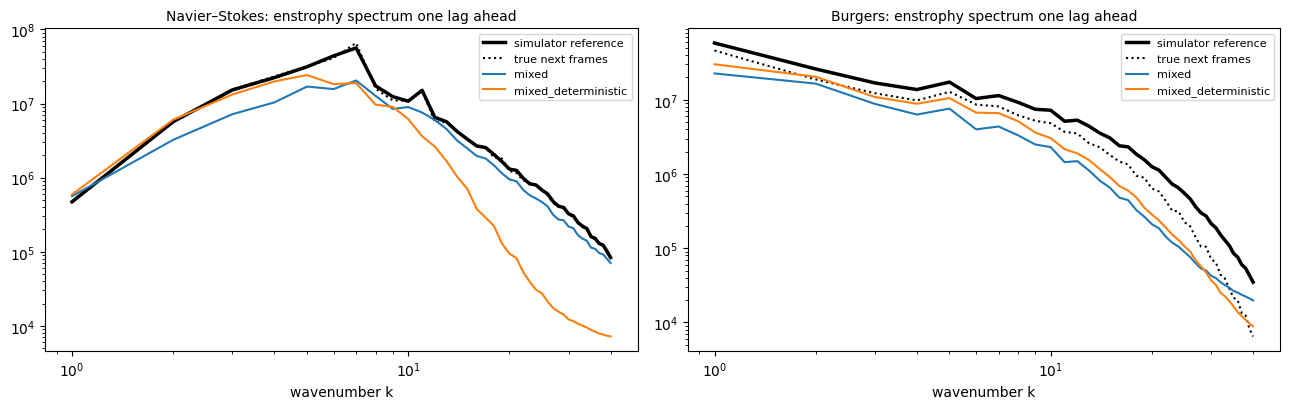

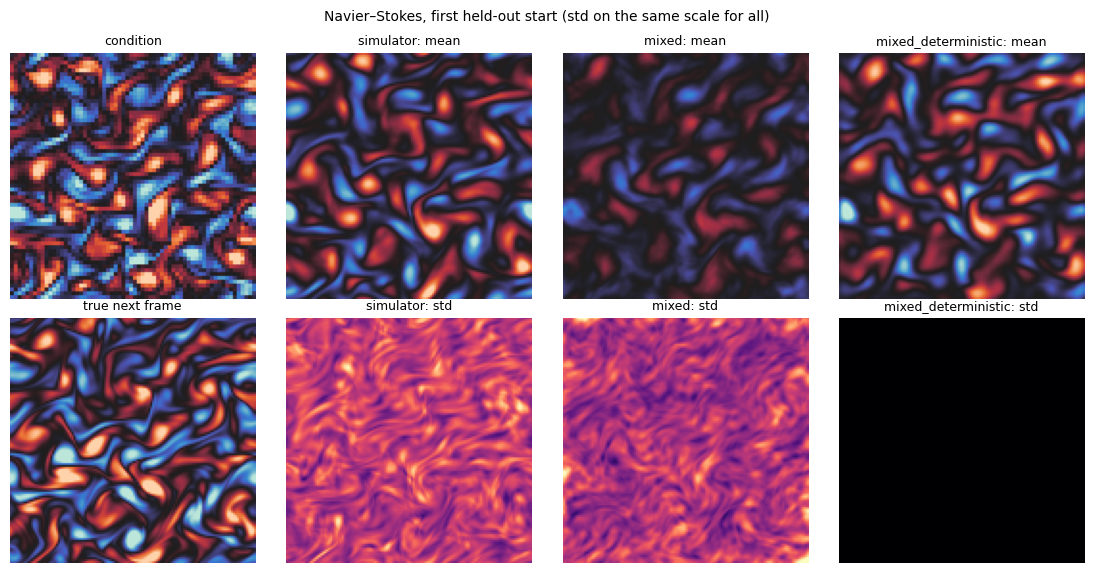

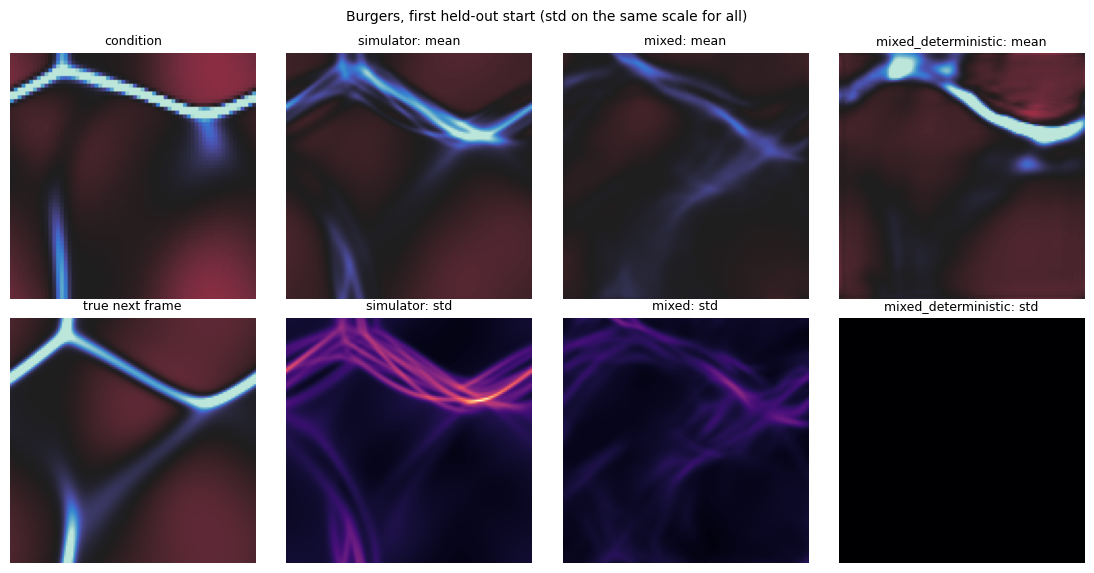

In [ ]:
fig, axes = plt.subplots(1, len(EVAL), figsize=(6.5 * len(EVAL), 4.2), squeeze=False)
k = np.arange(1, K_MAX + 1)
for ax, (system, e) in zip(axes[0], EVAL.items()):
    ax.loglog(k, enstrophy_spectrum(e["ref"])[1:], "k-", lw=2.5, label="simulator reference")
    ax.loglog(k, enstrophy_spectrum(e["truth"][:, None])[1:], "k:", label="true next frames")
    for (name, s_), ens in FORECASTS.items():
        if s_ == system:
            ax.loglog(k, enstrophy_spectrum(ens)[1:], label=name)
    ax.set_title(f"{system}: enstrophy spectrum one lag ahead", fontsize=10)
    ax.set_xlabel("wavenumber k")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for system, e in EVAL.items():
    ens_list = [("simulator", e["ref"])] + [(n, f) for (n, s_), f in FORECASTS.items() if s_ == system]
    fig, axes = plt.subplots(2, len(ens_list) + 1, figsize=(2.8 * (len(ens_list) + 1), 5.8), squeeze=False)
    axes[0, 0].imshow(e["cond"][0], cmap=sns.cm.icefire, vmin=-2, vmax=2)
    axes[0, 0].set_title("condition", fontsize=9)
    axes[1, 0].imshow(e["truth"][0], cmap=sns.cm.icefire, vmin=-2, vmax=2)
    axes[1, 0].set_title("true next frame", fontsize=9)
    vmax = float(e["ref"][0].std(0).max())
    for j, (n, f) in enumerate(ens_list, 1):
        axes[0, j].imshow(f[0].mean(0), cmap=sns.cm.icefire, vmin=-2, vmax=2)
        axes[0, j].set_title(f"{n}: mean", fontsize=9)
        axes[1, j].imshow(f[0].std(0), cmap="magma", vmin=0, vmax=vmax)
        axes[1, j].set_title(f"{n}: std", fontsize=9)
    for ax in axes.ravel():
        ax.axis("off")
    plt.suptitle(f"{system}, first held-out start (std on the same scale for all)", fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
@torch.no_grad()
def rollout_enstrophy(net, kind, cond, steps, em_steps):
    base = torch.as_tensor(cond, device=device)[:, None]      # (starts, 1, 128, 128)
    vals = []
    for _ in range(steps):
        x = sample_batch(net, kind, base, em_steps)
        vals.append(total_enstrophy(x[:, 0].float().cpu().numpy()))
        base, _ = utils.maybe_downsample(x, x, conf.lo_size, conf.hi_size)
    return float(np.mean(vals))


if RUN_ROLLOUT:
    for system, data in (("Navier–Stokes", nse_all), ("Burgers", b_all)):
        true_avg = float(total_enstrophy(model_view(data.reshape(-1, *data.shape[2:]).numpy())[1]).mean())
        rows = {}
        for name, (net, kind, systems) in MODELS.items():
            if system in systems:
                t0 = timer.time()
                torch.manual_seed(0)
                avg = rollout_enstrophy(net, kind, EVAL[system]["cond"], ROLLOUT_STEPS, ROLLOUT_EM_STEPS)
                rows[name] = {"average total enstrophy": avg, "relative error": abs(avg - true_avg) / true_avg,
                              "seconds": timer.time() - t0}
        print(f"\n{system}: data average total enstrophy {true_avg:.1f}; models iterated {ROLLOUT_STEPS} lags")
        display(pd.DataFrame(rows).T.round(4))


Navier–Stokes: data average total enstrophy 15612.0; models iterated 20 lags


,average total enstrophy,relative error,seconds
mixed,22266.5057,0.4262,664.5073
mixed_deterministic,5854.8883,0.6250,6.6286



Burgers: data average total enstrophy 18031.5; models iterated 20 lags


,average total enstrophy,relative error,seconds
mixed,21297.6123,0.1811,664.2419
mixed_deterministic,2985.9626,0.8344,6.6682


In [ ]:
# loss and gradient norm based on figure 8 of the paper
import csv
import time as timer

FIG8_EPOCHS = 50
FIG8_DATASETS = ("nse", "burgers", "mixed")
FIG8_BURGERS_FRACTION = 0.5
FIG8_DIR = "fig8"
BETAS = {"t": r"$\alpha=1-s,\ \beta=s,\ \sigma=1-s$", "t^2": r"$\alpha=1-s,\ \beta=s^2,\ \sigma=1-s$"}
os.makedirs(FIG8_DIR, exist_ok=True)


def split_file(dataset):
    """Write a dataset's training split (frames TRAIN_FRAMES), as the dataset cell does. Returns its path and the
    trajectory range of each system."""
    names = {"nse": ["Navier–Stokes"], "burgers": ["Burgers"], "mixed": ["Navier–Stokes", "Burgers"]}[dataset]
    files = {"Navier–Stokes": NSE_FILE, "Burgers": BURGERS_FILE}
    a, b = TRAIN_FRAMES
    parts, systems, first = [], {}, 0
    for name in names:
        data, t = torch.load(files[name])
        parts.append(data[:, a:b])
        systems[name] = (first, first + data.shape[0])
        first += data.shape[0]
    path = f"{FIG8_DIR}/{dataset}_train.pt"
    torch.save((torch.cat(parts, 0).clone(), t[a:b].clone()), path)
    return path, systems


def fig8_run(dataset, beta_fn, epochs, seed=0):
    """Train one model from scratch with their components; returns one row per step."""
    path, systems = split_file(dataset)
    c = main.Config(dataset="nse", debug=False, overfit=False, sigma_coef=1.0, beta_fn=beta_fn)
    c.data_fname, c.use_wandb = path, False
    c.batch_size = 32 if GPU_MEM_GB > 35 else 16 if GPU_MEM_GB > 20 else 8
    torch.manual_seed(seed)
    loader, _, _ = utils.get_forecasting_dataloader(c, shuffle=True)
    if dataset == "mixed" and FIG8_BURGERS_FRACTION is not None:
        pairs = loader.dataset
        per_traj = len(pairs) // sum(hi - lo for lo, hi in systems.values())
        lo, hi = systems["Burgers"]
        is_b = torch.zeros(len(pairs), dtype=torch.bool)
        is_b[lo * per_traj: hi * per_traj] = True
        w = torch.where(is_b, FIG8_BURGERS_FRACTION / is_b.sum(), (1 - FIG8_BURGERS_FRACTION) / (~is_b).sum())
        sampler = torch.utils.data.WeightedRandomSampler(w.double(), len(pairs), replacement=True,
                                                         generator=torch.Generator().manual_seed(seed))
        loader = torch.utils.data.DataLoader(pairs, batch_size=c.batch_size, sampler=sampler)
    net = utils.DriftModel(c).to(device)
    interp = interpolant.Interpolant(c)
    opt = torch.optim.AdamW(net.parameters(), lr=c.base_lr)
    U = torch.distributions.Uniform(low=c.t_min_train, high=c.t_max_train)
    rows, step = [], 0
    for epoch in range(epochs):
        for xlo, xhi in loader:
            with torch.no_grad():
                D = {"z0": xlo.to(device), "z1": xhi.to(device), "label": None, "N": xlo.shape[0]}
                D["t"] = U.sample(sample_shape=(D["N"],)).to(device)
                D["cond"] = D["z0"]
                D["noise"] = torch.randn_like(D["z0"])
                D = interp.interpolant_coefs(D)
                D["zt"] = interp.compute_zt(D)
                D["drift_target"] = interp.compute_target(D)
            net.train()
            out = net(D["zt"], D["t"], None, cond=D["cond"])
            loss = (out - D["drift_target"]).pow(2).sum(-1).sum(-1).sum(-1).mean()   # Trainer.training_step
            loss.backward()
            grad_norm = utils.clip_grad_norm(net, max_norm=c.max_grad_norm)        # Trainer.optimizer_step
            opt.step()
            opt.zero_grad(set_to_none=True)
            step += 1
            rows.append({"step": step, "epoch": step / len(loader), "loss": loss.item(),
                         "grad_norm": float(grad_norm)})
        if (epoch + 1) % 10 == 0:
            print(f"  {dataset}, beta={beta_fn}: epoch {epoch + 1}, "
                  f"mean loss {np.mean([r['loss'] for r in rows[-len(loader):]]):.1f}")
    del net, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return rows


FIG8 = {}
for dataset in FIG8_DATASETS:
    for beta_fn in BETAS:
        path = f"{FIG8_DIR}/{dataset}_{beta_fn.replace('^', '')}.csv"
        if os.path.exists(path):
            with open(path, newline="") as f:
                rows = [{k: float(v) for k, v in r.items()} for r in csv.DictReader(f)]
            print(f"{dataset}, beta={beta_fn}: read {len(rows)} steps from {path}")
        else:
            t0 = timer.time()
            rows = fig8_run(dataset, beta_fn, FIG8_EPOCHS)
            with open(path, "w", newline="") as f:
                writer = csv.DictWriter(f, list(rows[0]))
                writer.writeheader()
                writer.writerows(rows)
            print(f"{dataset}, beta={beta_fn}: {len(rows)} steps in {timer.time() - t0:.0f}s -> {path}")
        FIG8[dataset, beta_fn] = rows

SELF DEBUG IS False
OVERFIT MODE (USEFUL FOR DEBUGGING) IS False
NOT USING CLASSES IN UNET
Num params in main arch for drift is 29,988,753
  nse, beta=t: epoch 10, mean loss 5483.0
  nse, beta=t: epoch 20, mean loss 4182.3
  nse, beta=t: epoch 30, mean loss 4053.9


In [ ]:
# Table 2
def mean_error_without_noise(ens, ref):
    out = []
    for s in range(ens.shape[0]):
        m, r = ens[s].shape[0], ref[s].shape[0]
        noise_e = ens[s].var(0, ddof=1).sum() / m
        noise_r = ref[s].var(0, ddof=1).sum() / r
        num = ((ens[s].mean(0) - ref[s].mean(0)) ** 2).sum() - noise_e - noise_r
        den = (ref[s].mean(0) ** 2).sum() - noise_r
        out.append(np.sqrt(max(num, 0.0) / den) if den > 0 else np.nan)
    return np.array(out)


def fmt(v):
    return v if isinstance(v, str) else f"{v:.1e}"


ROWS = ["Short time L² error of mean", "   same, sampling noise removed", "Short time L² error of std",
        "Long time error of averaged total enstrophy"]
PAPER = {"paper: SDEs": ["1.1e-1", "—", "6.8e-2", "5.6e-3"], "paper: deterministic": ["2.3e-1", "—", "N/A", "3.0e-1"]}
for system, e in EVAL.items():
    rows, single = RESULTS.get(system, {}), {"Navier–Stokes": "nse", "Burgers": "burgers"}[system]
    columns = {}
    for dataset in (single, "mixed"):
        for label, name in (("SDE", dataset), ("deterministic", f"{dataset}_deterministic")):
            if name not in rows:
                continue
            rollout = ROLLOUT.get((name, system), "not run")
            columns[f"{label}, trained on {dataset}"] = [
                fmt(np.mean(rows[name]["mean_err"])),
                fmt(np.nanmean(mean_error_without_noise(FORECASTS[name, system], e["ref"]))),
                "N/A" if label == "deterministic" else fmt(np.mean(rows[name]["std_err"])), fmt(rollout)]
    floor = rows["simulator (perfect-model floor)"]
    columns["perfect model (simulator)"] = [fmt(np.mean(floor["mean_err"])),
                                            fmt(np.nanmean(mean_error_without_noise(e["control"], e["ref"]))),
                                            fmt(np.mean(floor["std_err"])), "—"]
    if system == "Navier–Stokes":
        columns.update(PAPER)
    print(f"\n{system}: lag {LAG} frames, {N_MEMBERS} members x {e['truth'].shape[0]} starts, "
          f"rollouts of {ROLLOUT_STEPS} lags")
    if not SIM_OK[system]:
        print("  caution: this system's simulator check failed, so the two short-time rows are uncertain")
    display(pd.DataFrame(columns, index=ROWS))